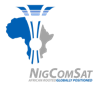 &nbsp;&nbsp; 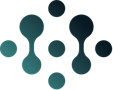

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/main/Jasons-Restructure/week-3/day-3-drift-and-cusum/4-instructor-only/W3D3-solution.ipynb)

> 🧑🏾‍🏫 **INSTRUCTOR SOLUTION.** Every blank is filled in. Don't share this with participants before the session ends.

# 🧾 Week 3 · Day 3: The Slow Creep: Drift and CUSUM

**Today:** some faults never shout. You'll build **CUSUM**, a detector that adds up small leftovers, catch an amplifier step that a 3σ rule can't see, and find when a battery started ageing faster.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (**Shift + Enter**) |
| ✍️ | Your turn: replace every `___` |
| ✅ / ❌ | The check tells you if you got it right |
| 🌶️ | Bonus for fast finishers |

> ## ⚠️ First: **File → Save a copy in Drive**
> Then run STEP 0. Keep `W3D3-rulebook.pdf` open next to you.

## ▶️ STEP 0: Set up (run once, and again after any restart)
You should see `✅ Ready!`. This cell also brings in three helpers you'll use today: `expected_temp`, `fade_rate`, `rolling_slope`.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def expected_temp(df):
    """'Normal' amplifier temperature for each day, learned from 2024 only:
    drive level + sun angle (a yearly wave) + slow ageing. Second pass ignores one-off spikes."""
    d = df.index.day_of_year.to_numpy()
    age = (df.index - pd.Timestamp("2024-01-01")).days.to_numpy()
    X = np.column_stack([np.ones(len(df)), df["rf_drive_pct"].to_numpy(),
                         np.sin(2 * np.pi * d / 365.25), np.cos(2 * np.pi * d / 365.25), age])
    y = df["twta_temp_c"].to_numpy()
    learn = df.index < "2025-01-01"
    coef, *_ = np.linalg.lstsq(X[learn], y[learn], rcond=None)
    r = y - X @ coef
    keep = learn & (np.abs(r) < 3 * r[learn].std())
    coef, *_ = np.linalg.lstsq(X[keep], y[keep], rcond=None)
    return pd.Series(X @ coef, index=df.index)

def fade_rate(s):
    """Slope of a straight line through the series, in units per YEAR."""
    x = np.arange(len(s))
    return np.polyfit(x, s.to_numpy(), 1)[0] * 365

def rolling_slope(s, window=90):
    """Trailing rolling slope (units per year): looks back only, never ahead."""
    x = np.arange(window)
    return s.rolling(window).apply(lambda w: np.polyfit(x, w, 1)[0] * 365, raw=True)

def _twta():
    return pd.read_csv(data_path("twta_thermal_daily"), parse_dates=["date"], index_col="date").asfreq("D")

def _resid_sigma():
    tw = _twta()
    r = tw["twta_temp_c"] - expected_temp(tw)
    r24 = r[:"2024-12-31"]
    return r, r24[r24.abs() < 3 * r24.std()].std()

def _cus(values, k):
    S, out = 0.0, []
    for x in values:
        S = max(0.0, S + x - k)
        out.append(S)
    return out

def practice_residuals():
    """The amplifier's calm leftovers (Jan 2024 to the day before the real step), with the known 2-day
    hot spike left out, plus a SMALL secret fault we add on purpose. Your job: find when it started."""
    r, s = _resid_sigma()
    p = r[:"2025-05-11"]
    p = p[~((p.index < "2025-01-01") & (p.abs() > 3 * s))].copy()
    p.loc["2025-02-10":] += 0.3
    return p

def _bat():
    return pd.read_csv(data_path("battery_health_daily"), parse_dates=["date"], index_col="date").asfreq("D")["est_capacity_ah"]

def _same_day(a, b):
    return pd.Timestamp(a).normalize() == pd.Timestamp(b).normalize()

def _c_a1(x):
    want = ("spike", "level shift", "drift")
    got = tuple(str(v).strip().lower().replace("-", " ").replace("_", " ") for v in x)
    wrong = [i + 1 for i, (g, w) in enumerate(zip(got, want)) if g != w]
    return not wrong, "Spike, level shift, drift: you can name all three shapes of trouble.", \
        f"Check statement(s) {wrong}. Choose from: spike, level shift, drift."

def _c_a2(x):
    want = _cus([0.3, -0.2, 0.4, 1.0, 1.2, 0.9, 1.1], 0.5)
    ok = len(x) == len(want) and all(v is not None for v in x) and np.allclose(x, want)
    return ok, "Your CUSUM works: [0, 0, 0, 0.5, 1.2, 1.6, 2.2]. Noise days stay at zero; the change piles up.", \
        "The line is S = max(0, S + x - k): add today's leftover, take away the slack, never go below zero."

def _c_a3(x):
    return tuple(int(v) for v in x) == (4, 7), \
        "Started day 4, alarm day 7. The alarm date is NOT the start date: CUSUM needs time to collect evidence.", \
        "Start = the day AFTER S was last zero. Alarm = the first day S is above h = 2."

def _c_a4(x):
    return str(x).strip().lower().strip("()") == "b", "Correct: k is slack, so ordinary noise doesn't pile up.", \
        "k is not the alarm line (that's h). Think: what stops small everyday wobble from adding up?"

def _c_b1(x):
    t = _twta()["twta_temp_c"]
    return int(x) == int((t > t.mean() + 3 * t.std()).sum()) == 0, \
        "Zero alarms in two years. The step hides inside the yearly swing: a whole-series 3σ rule is blind to it.", \
        "Count the days above the ceiling: (tw[\"twta_temp_c\"] > ceiling).sum()"

def _c_b2(x):
    t = _twta()["twta_temp_c"]
    pre, post = t["2025-04-12":"2025-05-11"], t["2025-05-12":"2025-06-10"]
    want = (post.mean() - pre.mean()) / pre.std()
    return abs(float(x) - want) < 0.05, f"{want:.1f}σ against its neighbours. A giant up close, a dwarf from far away. 🔭", \
        "(post.mean() - pre.mean()) / pre.std()"

def _c_b3(x):
    r, s = _resid_sigma()
    want = r["2025-05-12":].mean()
    return abs(float(x) - want) < 0.005, f"+{want:.2f} °C of leftovers after the step: almost exactly the +1.8 °C fault hidden in the file. 🎯", \
        "First expected = expected_temp(tw). Then resid[\"2025-05-12\":].mean()"

def _c_b4(x):
    r, s = _resid_sigma()
    return abs(float(x[0]) - 0.5 * s) < 1e-6 and abs(float(x[1]) - 5 * s) < 1e-6, \
        f"k = {0.5 * s:.3f} °C (slack) and h = {5 * s:.3f} °C (decision limit). Both measured in σ of the leftovers.", \
        "k = 0.5 * sigma and h = 5 * sigma"

def _c_b5(x):
    return _same_day(x, "2025-05-12"), "12 May 2025: the very first day of the step. Big steps get caught fast. 🚨", \
        "S[S > h].index.min() gives the first day S is above h."

def _c_b6(x):
    a, o = x
    return _same_day(a, "2025-02-13") and _same_day(o, "2025-02-10"), \
        "Alarm 13 Feb 2025, start traced back to 10 Feb 2025. Exactly where we hid it. Detective work! 🕵🏾", \
        "Alarm: Sp[Sp > h].index.min(). Start: the day after the last day S was 0 before the alarm."

def _c_c1(x):
    return int(x) == int((_bat() < 95).sum()) == 0, \
        "Zero days below 95 Ah. A threshold detector would sleep through the whole problem. 😴", \
        "(cap < 95).sum()"

def _c_c2(x):
    cap = _bat()
    b, a = fade_rate(cap[:"2025-03-31"]), fade_rate(cap["2025-04-01":])
    ok = abs(float(x[0]) - b) < 0.01 and abs(float(x[1]) - a) < 0.01
    return ok, f"{b:.2f} → {a:.2f} Ah per year: {a / b:.1f}× faster. No day is unusual; the SPEED changed.", \
        "fade_rate(cap[:\"2025-03-31\"]) and fade_rate(cap[\"2025-04-01\":])"

def _c_c3(x):
    s = rolling_slope(_bat(), 90)
    want = s[s < -3.0].index.min()
    return _same_day(x, want), f"{want.date()}: {(want - pd.Timestamp('2025-04-01')).days} days after the speed-up began. Trailing windows warn late, so plan for it.", \
        "WARNING_LINE should be -3.0 (minus three, in Ah per year)."

def _c_bonus(x):
    p = practice_residuals()
    r, s = _resid_sigma()
    S_, n = 0.0, 0
    for day, v in p.items():
        S_ = max(0.0, S_ + v - 0.5 * s)
        if S_ > 2 * s:
            n += day < pd.Timestamp("2025-02-10")
            S_ = 0.0
    return int(x) == n, f"{n} false alarms with h = 2σ (h = 5σ gave none). Fast, yes. But the duty engineer will stop picking up the phone. 📵", \
        "Count the alarm days that come BEFORE the start you found in B6."

CHECKS = {"A1": _c_a1, "A2": _c_a2, "A3": _c_a3, "A4": _c_a4, "B1": _c_b1, "B2": _c_b2, "B3": _c_b3, "B4": _c_b4,
          "B5": _c_b5, "B6": _c_b6, "C1": _c_c1, "C2": _c_c2, "C3": _c_c3, "BONUS": _c_bonus}
HINTS = {"A2": "Inside the loop: S = max(0, S + x - k)", "B6": "Give two dates: (practice_alarm, start)",
         "C2": "Give two numbers: (rate_before, rate_after)"}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


---
# Part A: CUSUM by hand (15 min) 🧾

### A1 ✍️ Name the shape
Three faults, three shapes. Write `"spike"`, `"level shift"` or `"drift"` for each:

1. One reading jumps way up, and the next day everything is back to normal.
2. The temperature steps up by 2 °C one day **and stays there**.
3. The battery loses capacity a little **faster** every month.

In [ ]:
s1 = "spike"
s2 = "level shift"
s3 = "drift"

check("A1", (s1, s2, s3))

### A2 ✍️ Write the one line that makes CUSUM work
Every day: **add today's leftover, take away the slack `k`, and never go below zero.**
In Python: `max(0, S + x - k)`. Put it in the blank inside the loop.

In [ ]:
def cusum(values, k):
    S = 0
    out = []
    for x in values:
        S = max(0, S + x - k)          # ✍️ the CUSUM line
        out.append(S)
    return out

toy = [0.3, -0.2, 0.4, 1.0, 1.2, 0.9, 1.1]      # 7 days of leftovers
print(cusum(toy, k=0.5))
check("A2", cusum(toy, k=0.5))

### A3 ✍️ When did it start, and when did the alarm ring?
▶️ Run the table first. Use **h = 2**. The change **started** the day *after* S was last zero. The **alarm** is the first day S is above h.

In [ ]:
assert cusum([1.0], 0.0)[0] == 1.0, "✍️ Do A2 first: write the CUSUM line, then run this again."

for day, (x, s) in enumerate(zip(toy, cusum(toy, k=0.5)), start=1):
    print(f"day {day}: leftover {x:+.1f}  ->  S = {s:.1f}" + ("   🚨 above h=2" if s > 2 else ""))

In [ ]:
start_day = 4
alarm_day = 7

check("A3", (start_day, alarm_day))

### A4 ✍️ What is the slack `k` for?
- **a)** it is the alarm threshold
- **b)** it is slack, so ordinary everyday noise does not pile up
- **c)** it is the value S resets to after an alarm

Type the letter in quotes.

In [ ]:
k_is_for = "b"

check("A4", k_is_for)

---
# Part B: The amplifier's sneaky step (30 min) 🌡️

**The data:** `twta_thermal_daily` (the **week-04** version, which `data_path` gives you by default): two years of the TWTA amplifier's daily temperature and its RF drive level.

### B1 ✍️ Does a whole-series 3σ rule see anything?
▶️ The cell computes the ceiling (mean + 3σ of the whole series). Count the days **above** it.

In [ ]:
tw = pd.read_csv(data_path("twta_thermal_daily"), parse_dates=["date"], index_col="date").asfreq("D")
ceiling = tw["twta_temp_c"].mean() + 3 * tw["twta_temp_c"].std()
print(f"3σ ceiling: {ceiling:.2f} °C   hottest day: {tw['twta_temp_c'].max():.2f} °C")

tw["twta_temp_c"].plot(title="TWTA temperature, two years", lw=1)
plt.axhline(ceiling, color="#E5484D", ls="--", label="3σ ceiling")
plt.axvline(pd.Timestamp("2025-05-12"), color="#C77700", ls=":", label="12 May 2025")
plt.legend(); plt.ylabel("°C"); plt.show()

In [ ]:
n_point_alarms = (tw["twta_temp_c"] > ceiling).sum()          # how many days are above the ceiling?

check("B1", n_point_alarms)

### B2 ✍️ Zoom in: how big is the step against its neighbours?
Compare the 30 days after 12 May 2025 with the 30 days before, in units of the **local** wobble: `(post.mean() - pre.mean()) / pre.std()`.

In [ ]:
t = tw["twta_temp_c"]
pre = t["2025-04-12":"2025-05-11"]
post = t["2025-05-12":"2025-06-10"]

jump_in_sigma = (post.mean() - pre.mean()) / pre.std()
print(f"before {pre.mean():.2f} °C  after {post.mean():.2f} °C")
check("B2", jump_in_sigma)

### B3 ✍️ Take away what you already know
`expected_temp(tw)` (from STEP 0) gives the **normal** temperature for every day, learned from 2024: drive level + sun angle + slow ageing.
The **leftovers** (residuals) = actual − expected. Fill in `expected`, then the average leftover from 12 May 2025 onward.

In [ ]:
expected = expected_temp(tw)
assert expected is not None, "✍️ Fill in expected first: expected_temp(tw)"
resid = tw["twta_temp_c"] - expected

r24 = resid[:"2024-12-31"]
sigma = r24[r24.abs() < 3 * r24.std()].std()      # the normal wobble of the leftovers (2024, spikes ignored)
print(f"sigma of leftovers: {sigma:.3f} °C")

after_mean = resid["2025-05-12":].mean()
check("B3", after_mean)

### B4 ✍️ Set the two knobs from σ
Slack **k = 0.5 × σ**. Decision limit **h = 5 × σ**.

In [ ]:
k = 0.5 * sigma
h = 5 * sigma

check("B4", (k, h))

### B5 ✍️ Run CUSUM on 2025 and find the first alarm
We start watching on 1 Jan 2025 (the model learned from 2024). `S[S > h].index.min()` gives the first day S is above h.

In [ ]:
assert k is not None and h is not None, "✍️ Do B4 first."
r25 = resid["2025-01-01":]
S = pd.Series(cusum(r25.to_numpy(), k), index=r25.index)

S["2025-04-15":"2025-05-20"].plot(title="CUSUM around the step", lw=2)
plt.axhline(h, color="#E5484D", ls="--", label="h"); plt.legend(); plt.show()

first_alarm = S[S > h].index.min()
check("B5", first_alarm)

### B6 ✍️ The secret fault 🕵🏾
`practice_residuals()` gives you the calm leftovers **before** the real step, with a **small** fault (about 1.5σ) hidden somewhere. ▶️ The first lines show the point rule seeing almost nothing.
Find (1) the **alarm date** and (2) the **start date** = the day after S was last zero before the alarm.

In [ ]:
p = practice_residuals()
print("days above the 3σ point-rule line:", int((p > 3 * sigma).sum()))
Sp = pd.Series(cusum(p.to_numpy(), k), index=p.index)

practice_alarm = Sp[Sp > h].index.min()
before = Sp[:practice_alarm]
last_zero = before[before == 0].index.max()
start = last_zero + pd.Timedelta(days=1)                 # the day AFTER last_zero  (hint: last_zero + pd.Timedelta(days=1))

print("alarm:", practice_alarm, "  start:", start)
check("B6", (practice_alarm, start))

---
# Part C: The battery that's ageing faster (15 min) 🔋

**The data:** `battery_health_daily`, the **week-04** version (the default). ⚠️ The week-03 file with the same name is a clean twin **without** today's problem.

### C1 ✍️ Does a 95 Ah threshold ever fire?

In [ ]:
cap = pd.read_csv(data_path("battery_health_daily"), parse_dates=["date"], index_col="date").asfreq("D")["est_capacity_ah"]
cap.plot(title="Battery usable capacity", lw=1.5)
plt.axhline(95, color="#E5484D", ls="--", label="95 Ah alarm line")
plt.legend(); plt.ylabel("Ah"); plt.show()

In [ ]:
days_below_95 = (cap < 95).sum()

check("C1", days_below_95)

### C2 ✍️ Measure the speed: before vs after April 2025
`fade_rate(series)` fits a straight line and returns the change **per year**. Use `cap[:"2025-03-31"]` and `cap["2025-04-01":]`.

In [ ]:
rate_before = fade_rate(cap[:"2025-03-31"])
rate_after = fade_rate(cap["2025-04-01":])

print(f"{rate_before:.2f} Ah/yr  ->  {rate_after:.2f} Ah/yr" if rate_after is not None else "")
check("C2", (rate_before, rate_after))

### C3 ✍️ Watch the speedometer, not the fuel gauge
A **90-day trailing rolling slope** shows the speed every day. Set a warning line at **−3.0 Ah per year** and find the first day the slope drops below it.

In [ ]:
slope90 = rolling_slope(cap, 90)

WARNING_LINE = -3.0
assert WARNING_LINE is not None, "✍️ Fill in WARNING_LINE first."
slope90["2024-01-01":].plot(title="90-day rolling slope of capacity (Ah per year)", lw=2)
plt.axhline(WARNING_LINE, color="#E5484D", ls="--"); plt.show()

first_warning = slope90[slope90 < WARNING_LINE].index.min()
print("first warning:", first_warning, "  days after 1 Apr 2025:", (first_warning - pd.Timestamp("2025-04-01")).days)
check("C3", first_warning)

---
## 🌶️ Pepper task: how noisy is a jumpy h?
`alarm_days` below runs CUSUM **with a reset** after every alarm (what you do once someone has checked it).
Run it on the practice leftovers with **h = 2σ** instead of 5σ, and count the alarms that come **before** the start you found in B6. Those are false alarms.

In [ ]:
def alarm_days(x, k, h):
    S, out = 0.0, []
    for day, v in x.items():
        S = max(0.0, S + v - k)
        if S > h:
            out.append(day)
            S = 0.0          # reset after each alarm
    return out

jumpy = alarm_days(p, k, 2 * sigma)
false_alarms = sum(day < start for day in jumpy)          # how many of the jumpy alarms come before `start`?
check("BONUS", false_alarms)

---
## 🏁 Final project · Checkpoint 2: 📥 Data in hand
Tick these off with your trainer today (on **your** data, on NIGCOMSAT systems, not in Colab):

- [ ] Your unit head's **email reply** agreeing the process, the data and who it's for
- [ ] Data loaded with a `DatetimeIndex`, one time zone, and `.asfreq()`
- [ ] Profiled: **rows, date range, gaps, duplicated timestamps**
- [ ] One honest plot with your **operational threshold** drawn on it
- [ ] Raw data **not** on GitHub; nothing restricted pasted into an AI tool

Next checkpoint: **Week 4 · Day 3: method drafted** 🛠️

## Finish line
▶️ Run the scoreboard, then **File → Save**.

In [ ]:
scoreboard()

### 📝 What you learned today
- **Three shapes:** spike (point rule), **level shift** (CUSUM), **drift** (rolling slope).
- A shift can be **6.9σ** against its neighbours yet invisible to a whole-series 3σ rule.
- **Take away what you already know first** (drive, sun angle, ageing), then watch the leftovers.
- **CUSUM:** `S = max(0, S + leftover − k)`, k = 0.5σ slack, h = 5σ evidence. Reset after an alarm is handled.
- **Alarm date ≠ start date.** Trace the start back to the day after S was last zero.
- Low h = fast but noisy; high h = calm but late. Choose on purpose.

**Next time:** *Scoring a Detector + Quiz 2*. The answer key comes out. 🔑

<sub>Data: synthetic teaching datasets from the original Week 4 code book (`Time-series/week-04`). Safe to use in AI assistants. Real NIGCOMSAT data is not.</sub>